# 12 · Recommender systems: the industry funnel, with LLMs where they help

YouTube, Netflix and Spotify all answer the same question millions of times a second: *of everything we have, what should this person see now?* None of them answers it with one model. They use a **funnel**: cheap models narrow a huge catalog to a few hundred candidates, a more expensive model orders those candidates, and a final layer applies business rules, diversity and exploration. Language models now appear at several points of that funnel.

In this notebook we build that funnel on **real data**, MovieLens-1M (1 million ratings from 6,040 users on 3,706 movies), and measure every stage:

| stage | what we build | tool |
|---|---|---|
| sequential retrieval | **SASRec**: a decoder-only transformer whose vocabulary is the catalog | PyTorch (`TransformerLM` from notebook 02) |
| embedding retrieval | a **two-tower** model and an approximate nearest-neighbour index | PyTorch, FAISS |
| content retrieval | item text embeddings, enriched with **keywords written by an LLM** | Ollama embeddings |
| ranking | a gradient-boosted **learning-to-rank** model over all candidates | LightGBM (LambdaMART) |
| re-ranking | an **exploration slot** for new items, **MMR** for diversity | numpy |
| LLM layer | **conversational requests** turned into filters, and **grounded explanations** | LangChain + `qwen2.5:3b` |

One rule runs through the notebook: **a stage only goes into the system if it measurably helps on held-out data.** The previous version of this notebook let an LLM re-order the recommendations and the results got worse; here every stage has to earn its place, and when one does not, the notebook says so.

## Background: how industrial recommenders are built

### The problem and why it is hard

A recommender estimates, for a user $u$ in a context $c$, how likely each item $i$ is to be the "right" next thing (watched, played, bought, enjoyed), and shows the top few. Three facts shape every real system:

1. **Scale.** Catalogs have millions of items and the answer is needed in tens of milliseconds, so you cannot run an expensive model on every item.
2. **Feedback is implicit and biased.** We mostly observe what people clicked or watched, not what they disliked, and only among what the system already showed them (exposure bias). Popular items get more exposure and therefore more data (popularity bias).
3. **The world changes.** New items arrive every day with no interaction history (**cold start**), and tastes drift.

### The funnel: candidate generation, ranking, re-ranking

The answer to scale, popularised by YouTube's paper (Covington, Adams and Sargin, 2016, *Deep Neural Networks for YouTube Recommendations*), is to split the problem:

```
catalog (millions)  --candidate generation-->  hundreds  --ranking-->  tens  --re-ranking-->  the page
   cheap, high recall,                         expensive, precise,       rules, diversity,
   several sources                             many features             exploration, explanations
```

- **Candidate generation (retrieval)** must not miss good items (high *recall*), and must be cheap per item. Typical sources: a two-tower model with an approximate nearest-neighbour (ANN) index, a sequential model, item-to-item co-occurrence ("people who watched X watched Y"), content similarity, trending and popular lists. Each source catches different things, so systems take the **union**.
- **Ranking** looks at only a few hundred candidates, so it can afford many features and a heavier model. For years the standard has been **gradient-boosted trees trained to rank** (LambdaMART), and deep ranking models (Wide & Deep, DCN, DLRM) at the largest scales.
- **Re-ranking** turns a scored list into a page: remove near-duplicates, mix genres (diversity), reserve slots for new or uncertain items (exploration), apply business rules, and attach explanations.

What makes the funnel work is that each stage is evaluated by a different metric: retrieval by **recall@K** of the candidate set (the ranker cannot recover what retrieval missed), ranking by **nDCG@10** or **hit@10** of the final list.

### What the big platforms run today

| company | what is public | the idea we borrow |
|---|---|---|
| YouTube | two-tower retrieval with sampling-bias correction (Yi et al., 2019); multi-task ranking (Zhao et al., 2019) | the funnel; two-tower + ANN retrieval |
| Netflix | many specialised models being consolidated into a **foundation model**: an autoregressive transformer over each member's interaction sequence, with item metadata so new titles get embeddings (Netflix Tech Blog, 2025) | sequential modelling as language modelling; metadata for cold start |
| Spotify | contextual bandits for the home page (BaRT, McInerney et al., 2018); LLM-written explanations and narration for the AI DJ (2024-2025) | exploration slots; LLMs for explanations |
| Meta | **HSTU**, a generative sequential transducer that scales like an LLM (Zhai et al., 2024, *Actions Speak Louder than Words*) | "the vocabulary is the catalog" |

The trend is clear: **the sequence of a user's actions is treated like a sentence**, and the techniques of this course (decoder-only transformers, next-token prediction, embeddings) transfer directly. LLMs proper are used where language matters: understanding requests, describing items, and explaining recommendations.

### How we evaluate (and why this protocol)

- **Leave-last-two in time order.** For every user, the last interaction is the test target, the previous one the validation target, everything before is history. Predicting the *next* event from the past is what a live system does; a random split would leak the future.
- **Full ranking.** The model ranks all 3,706 movies and we look at where the true next movie lands. Many papers rank it against 100 random negatives instead, which inflates the numbers and can even change which model looks best (Krichene and Rendle, 2020, *On Sampled Metrics for Item Recommendation*).
- **Metrics.** *hit@10* is the fraction of users whose next movie is in the top 10, the "does it appear in the row" view. *nDCG@10* also rewards putting it high: a hit at position $p$ is worth $1/\log_2(p+1)$, so position 1 counts 1.0, position 3 counts 0.5 and position 10 counts 0.29 (with one relevant item the ideal DCG is 1, so no normalisation is needed). *MRR* averages $1/p$ without a cut-off.
- **Segments.** We hold out 10 % of the movies as *cold* (never seen in training, like new releases) and report warm and cold targets separately, because an average over everything hides the cold-start problem completely.
- **Uncertainty.** Every comparison between two systems is a **paired bootstrap** over users (notebook 10, `paired_bootstrap_diff`): if the 95 % interval of the difference contains 0, we do not claim an improvement.

**References.** Covington et al. 2016; Kang and McAuley 2018 (*Self-Attentive Sequential Recommendation*, SASRec); Klenitskiy and Vasilev 2023 (*Turning Dross Into Gold Loss: is BERT4Rec really better than SASRec?*); Yi et al. 2019 (*Sampling-Bias-Corrected Neural Modeling for Large Corpus Item Recommendations*); Burges 2010 (*From RankNet to LambdaRank to LambdaMART*); Krichene and Rendle 2020; Carbonell and Goldstein 1998 (MMR); Harper and Konstan 2015 (*The MovieLens Datasets*).

In [1]:
import os, sys, math, time, random, copy
ROOT = os.path.abspath(".")
while not os.path.isdir(os.path.join(ROOT, "llm_edu_suite")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)                    # climb from notebooks/<topic>/ up to the repo root
sys.path.insert(0, ROOT)                            # so that `import llm_edu_suite` works from any notebook
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from llm_edu_suite.utils import seed_everything, get_device, count_params, human
seed_everything(0)
device = get_device()
print("torch", torch.__version__, "| device", device)

torch 2.14.1+cu130 | device cuda


In [2]:
import json, re
from llm_edu_suite.recsys import download_movielens_1m, load_movielens_1m, temporal_split, target_ranks, rank_metrics
from llm_edu_suite.evaluation import bootstrap_ci, paired_bootstrap_diff
from llm_edu_suite.model import ModelConfig, TransformerLM
from llm_edu_suite.config import setup, get_llm, get_embeddings
info = setup(project="llm-edu-suite-12-recsys", quiet=True)     # LangSmith traces of the LLM calls in section 8, if configured
if device == "cuda":
    torch.cuda.set_per_process_memory_fraction(0.5)    # leave room on a 6 GB card for Ollama in the LLM sections
COLORS = {"popularity": "#9aa0a6", "itemknn": "#7f8c8d", "content": "#c69214", "content+llm": "#e67e22", "sasrec": "#1a73e8",
          "twotower": "#5e97f6", "ranker": "#188038", "explore": "#d93025"}
def style(ax):
    ax.grid(alpha=.3); ax.spines[["top", "right"]].set_visible(False)

ml = load_movielens_1m(download_movielens_1m())      # downloaded once into data/cache/ (MovieLens may not be redistributed)
sp = temporal_split(ml, cold_frac=0.1, seed=0)
N, users, cold = ml.n_items, sp["users"], sp["cold"]
train, valid, test = sp["train"], sp["valid"], sp["test"]
n_events = sum(len(v) for v in ml.events.values())
print(f"{n_events:,} ratings | {len(users):,} users | {N:,} movies | {len(cold)} movies held out as cold (new releases)")
print(f"median history length {np.median([len(h) for h, _ in test]):.0f} | test targets that are cold: {sum(t in cold for _, t in test)}")
print("a user's last five movies:", [ml.titles[i] for i in test[0][0][-5:]], "-> next:", ml.titles[test[0][1]])

1,000,209 ratings | 6,040 users | 3,706 movies | 370 movies held out as cold (new releases)
median history length 84 | test targets that are cold: 747
a user's last five movies: ["Bug's Life, A (1998)", 'Antz (1998)', 'Hunchback of Notre Dame, The (1996)', 'Hercules (1997)', 'Mulan (1998)'] -> next: Pocahontas (1995)


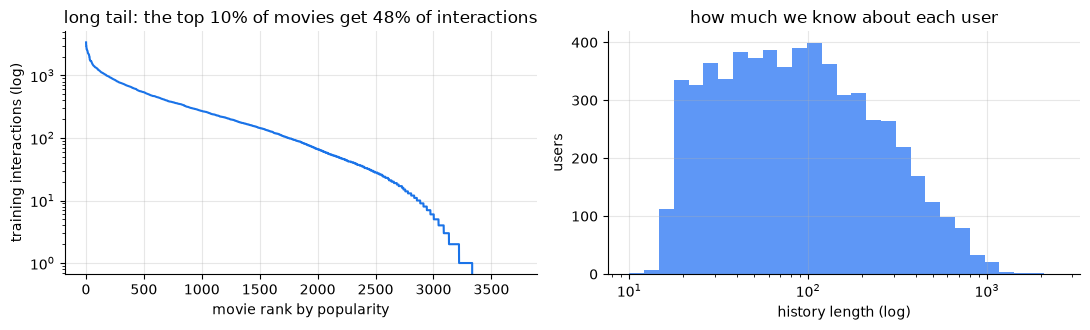

In [3]:
# Item metadata as tensors: genre multi-hot, release year, cold flag. Index 0 is padding.
GEN = ml.genre_names; gidx = {g: k for k, g in enumerate(GEN)}
G = torch.zeros(N + 1, len(GEN), device=device)
for i, gs in enumerate(ml.genres):
    for g in gs: G[i, gidx[g]] = 1
YR = torch.tensor(ml.years, dtype=torch.float, device=device)
YEAR_BUCKET = ((YR - 1919) // 5).clamp(0, 16).long()
COLD = torch.zeros(N + 1, dtype=torch.bool, device=device); COLD[list(cold)] = True
pop = torch.tensor(np.bincount([i for s in train for i in s], minlength=N + 1), dtype=torch.float, device=device)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
counts = np.sort(pop[1:].cpu().numpy())[::-1]
ax[0].plot(np.arange(1, N + 1), counts, color=COLORS["sasrec"]); ax[0].set_yscale("log")
ax[0].set_xlabel("movie rank by popularity"); ax[0].set_ylabel("training interactions (log)")
share = counts[: N // 10].sum() / counts.sum()
ax[0].set_title(f"long tail: the top 10% of movies get {share:.0%} of interactions")
ax[1].hist([len(h) for h, _ in test], bins=np.logspace(1, 3.4, 30), color=COLORS["twotower"]); ax[1].set_xscale("log")
ax[1].set_xlabel("history length (log)"); ax[1].set_ylabel("users"); ax[1].set_title("how much we know about each user")
for a in ax: style(a)
plt.tight_layout(); plt.show()

## 1. Evaluation harness and baselines

Every model below is a function from a batch of histories to a score for every movie. The harness masks what each user has already seen, finds the rank of the true next movie among all the others, and keeps the per-user ranks, so that we can report any metric, split by segment and bootstrap differences.

Two baselines set the floor. **Popularity** recommends the same most-watched movies to everyone; it is surprisingly hard to beat on hit rate because of the long tail above. **ItemKNN** is the classic "people who watched X also watched Y": the cosine similarity between the columns of the user-item matrix, summed over the user's recent movies with a recency decay. It is what Amazon popularised in 2003 (Linden, Smith and York, *Item-to-Item Collaborative Filtering*) and it remains a strong, cheap candidate source.

In [4]:
RANKS = {}                                         # system name -> per-user rank of the test target (0 = top)
TGT = np.array([t for _, t in test]); IS_COLD = np.array([t in cold for t in TGT])

def ranks_for(score_fn, split, B=512):
    out = []
    for b in range(0, len(split), B):
        H = [h for h, _ in split[b:b + B]]
        out.append(target_ranks(score_fn(H), H, [t for _, t in split[b:b + B]]).cpu())
    return torch.cat(out).numpy()

def summary(name, r, quiet=False):
    m = rank_metrics(r); row = {}
    for seg, mask in (("all", np.ones_like(IS_COLD)), ("warm", ~IS_COLD), ("cold", IS_COLD)):
        row[seg] = (m["hit@10"][mask].mean(), m["ndcg@10"][mask].mean())
    if not quiet:
        print(f"{name:26s} hit@10 {row['all'][0]:.3f}  ndcg@10 {row['all'][1]:.3f}  mrr {m['rr'].mean():.3f}"
              f"  | warm hit@10 {row['warm'][0]:.3f} | cold hit@10 {row['cold'][0]:.3f}")
    return row

def recency(h, L=20, decay=0.9):
    h = h[-L:]
    return torch.tensor(h, device=device), torch.tensor([decay ** (len(h) - 1 - p) for p in range(len(h))], device=device)

def popularity_scores(H):
    return torch.log1p(pop).repeat(len(H), 1)

X = torch.zeros(len(train), N + 1, device=device)
for r_, s in enumerate(train): X[r_, s] = 1
Xn = X / (X.norm(dim=0, keepdim=True) + 1e-8)
ITEM_SIM = Xn.T @ Xn; ITEM_SIM.fill_diagonal_(0); del X, Xn
def itemknn_scores(H):
    out = torch.zeros(len(H), N + 1, device=device)
    for j, h in enumerate(H):
        if h:
            items, w = recency(h); out[j] = (ITEM_SIM[items] * w[:, None]).sum(0)
    return out

for name, fn in (("popularity", popularity_scores), ("itemknn", itemknn_scores)):
    RANKS[name] = ranks_for(fn, test); summary(name, RANKS[name])

popularity                 hit@10 0.036  ndcg@10 0.018  mrr 0.019  | warm hit@10 0.041 | cold hit@10 0.000


itemknn                    hit@10 0.125  ndcg@10 0.067  mrr 0.059  | warm hit@10 0.143 | cold hit@10 0.000


## 2. Sequential retrieval: SASRec is a language model over movies

**The idea.** Treat a user's history as a sentence whose words are movie ids, and train a decoder-only transformer to predict the next "word". That is SASRec (Kang and McAuley, 2018), and it is exactly the `TransformerLM` from notebook 02 with `vocab_size = n_items + 1`: causal self-attention lets the representation at each position look at everything the user did before, the output layer gives a score for every movie, and the loss is cross-entropy against the movie that came next.

**Why it works so well.** Taste is sequential: what you watched last predicts what you watch next much better than an unordered bag of everything you ever liked (franchises, moods, a weekend binge of one genre). Attention weighs the history adaptively, like a learned, context-dependent recency.

**The training detail that matters most.** The original SASRec used a binary loss with one sampled negative per positive. Training with the **full softmax cross-entropy** over the catalog (the language-model loss) is much stronger: Klenitskiy and Vasilev (2023) report hit@10 rising from 0.250 to 0.315 on this dataset with the same architecture. With 3,706 movies the full softmax is cheap. At YouTube or Netflix scale it is not, and they use **sampled softmax with a correction for how often each item is sampled** (the $\log Q$ correction, Yi et al., 2019).

We use the paper's shape (2 layers, 64 dimensions, a 200-movie window, dropout 0.2) and **early stopping on validation nDCG**: we evaluate every 500 steps and keep the best checkpoint, the standard practice in the literature.

In [5]:
L = 200
def pad_left(batch, n):
    """Left-pad (or truncate) histories to length n, so the most recent movie is always in the last position."""
    out = torch.zeros(len(batch), n, dtype=torch.long)
    for i, s in enumerate(batch):
        s = s[-n:]
        if s: out[i, n - len(s):] = torch.tensor(s)
    return out

def train_sasrec(seqs, max_steps=6000, eval_every=500, patience=3, seed=0, eval_split=None, log=True):
    seed_everything(seed)
    model = TransformerLM(ModelConfig(vocab_size=N + 1, max_seq_len=L, d_model=64, n_layers=2, n_heads=4, n_kv_heads=4, dropout=0.2)).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.01)
    pool = [s for s in seqs if len(s) >= 2]; rng = random.Random(seed)
    best, best_state, bad, curve = -1.0, None, 0, []
    for step in range(1, max_steps + 1):
        model.train()
        seq = pad_left(rng.sample(pool, 128), L + 1).to(device)
        x, y = seq[:, :-1], seq[:, 1:].clone(); y[(y == 0) | (x == 0)] = -100     # no loss on padding
        with torch.autocast(device, dtype=torch.bfloat16, enabled=device == "cuda"):
            _, loss = model(x, y)
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
        if eval_split is not None and step % eval_every == 0:
            model.eval(); score = scorer(model)
            nd = rank_metrics(ranks_for(score, eval_split))["ndcg@10"].mean(); curve.append((step, loss.item(), nd))
            if log: print(f"step {step:5d}  loss {loss.item():.3f}  valid ndcg@10 {nd:.4f}")
            if nd > best: best, bad, best_state = nd, 0, copy.deepcopy(model.state_dict())
            else:
                bad += 1
                if bad >= patience: break
    if best_state is not None: model.load_state_dict(best_state)
    model.eval()
    return model, curve

def scorer(model):
    def score(H):
        with torch.no_grad(), torch.autocast(device, dtype=torch.bfloat16, enabled=device == "cuda"):
            logits, _ = model(pad_left(H, L).to(device))
        return logits[:, -1].float()
    return score

t0 = time.time()
sasrec, curve = train_sasrec(train, eval_split=valid)
sasrec_scores = scorer(sasrec)
print(f"trained in {time.time() - t0:.0f}s, best checkpoint at step {max(curve, key=lambda c: c[2])[0]}")
RANKS["sasrec"] = ranks_for(sasrec_scores, test); summary("sasrec", RANKS["sasrec"])

step   500  loss 5.511  valid ndcg@10 0.1546


step  1000  loss 5.288  valid ndcg@10 0.1668


step  1500  loss 5.198  valid ndcg@10 0.1738


step  2000  loss 5.319  valid ndcg@10 0.1746


step  2500  loss 5.117  valid ndcg@10 0.1753


step  3000  loss 5.093  valid ndcg@10 0.1753


... (4 outputs left out)

step  5500  loss 5.051  valid ndcg@10 0.1796


step  6000  loss 5.103  valid ndcg@10 0.1773
trained in 259s, best checkpoint at step 5500


sasrec                     hit@10 0.293  ndcg@10 0.172  mrr 0.148  | warm hit@10 0.334 | cold hit@10 0.000


{'all': (np.float64(0.29304635761589404), np.float64(0.17197712742041488)),
 'warm': (np.float64(0.33440392971849614), np.float64(0.19624822399760172)),
 'cold': (np.float64(0.0), np.float64(0.0))}

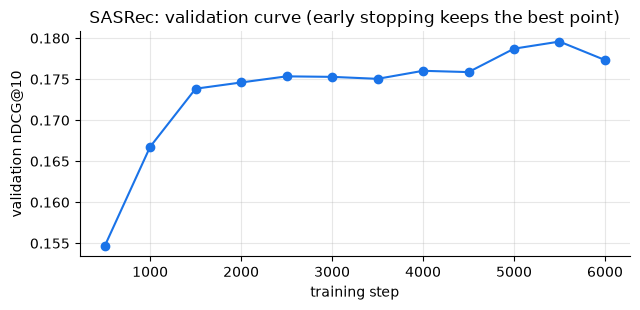

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 3.2))
st_, lo_, nd_ = zip(*curve)
ax.plot(st_, nd_, "o-", color=COLORS["sasrec"]); ax.set_xlabel("training step"); ax.set_ylabel("validation nDCG@10")
ax.set_title("SASRec: validation curve (early stopping keeps the best point)"); style(ax)
plt.tight_layout(); plt.show()

**What the numbers say.** Validation nDCG@10 climbs quickly to about 0.175 in the first 1,500 steps and then creeps up; early stopping kept the checkpoint at step 5,500 (0.180). On test, SASRec reaches **hit@10 0.293 and nDCG@10 0.172**, more than twice ItemKNN (0.125) and eight times popularity (0.036). That sits inside the range published for this dataset with full ranking (about 0.29 to 0.32 for SASRec trained with cross-entropy), so our small transformer is a fair baseline, not a straw man.

Two things to notice. First, **cold hit@10 is exactly 0**: SASRec's output layer has a row for every movie, but the rows of movies nobody watched in training were never trained, so a new movie is never ranked high. Second, GPU training is not bit-for-bit reproducible: in other executions of this notebook the curve peaked earlier and the test hit@10 came out at 0.290 or 0.294. Differences of that size between two systems mean nothing, which is why every comparison below comes with an interval.

## 3. Item content: metadata, plus keywords written by an LLM

Collaborative models learn only from co-occurrence, so a movie nobody has watched yet has no usable vector. **Content** fixes that: describe each item in text, embed the text, and similar items get similar vectors from day one. This is how Netflix's foundation model gives brand-new titles an embedding, and what most "cold-start" components do.

MovieLens only has a title, a year and genres, which is thin. Here is where an LLM helps cheaply and **offline**: we asked `qwen2.5:7b` once for 8 to 12 keywords per movie (subgenre, tone, themes, setting, era, audience) and stored them in `data/recsys/ml1m_llm_keywords.json` (`scripts/generate_item_keywords.py`, about an hour on a laptop GPU). This "LLM as feature generator" pattern is the best-supported way to use LLMs in recommendation at a reasonable cost (KAR, Xi et al., 2023, reported online A/B gains at Huawei; LLMRec, Wei et al., 2024).

Two cautions, both visible below. The prompt forbids names of people, because small models invent directors and actors with complete confidence. And for obscure films the keywords can simply be wrong; we measure whether they help instead of assuming it.

In [7]:
KEYWORDS = json.load(open(os.path.join(ROOT, "data", "recsys", "ml1m_llm_keywords.json"), encoding="utf-8"))
print(f"LLM keywords for {sum(t in KEYWORDS for t in ml.titles[1:])} of {N} movies")
for t in ["Toy Story (1995)", "Ice Storm, The (1997)", "Battleship Potemkin, The (Bronenosets Potyomkin) (1925)", "Ref, The (1994)"]:
    print(f"  {t[:45]:45s} {KEYWORDS.get(t, '-')}")

emb = get_embeddings()
def embed_items(mode):
    """nomic-embed-text expects a task prefix: search_document for the things being searched."""
    text = {"meta": lambda i: f"{ml.titles[i]}. Genres: {', '.join(ml.genres[i])}.",
            "meta+llm": lambda i: f"{ml.titles[i]}. Genres: {', '.join(ml.genres[i])}. Keywords: {KEYWORDS.get(ml.titles[i], '')}",
            "llm": lambda i: KEYWORDS.get(ml.titles[i], "")}[mode]
    docs = [f"search_document: {text(i)}" for i in range(1, N + 1)]
    V = np.zeros((N + 1, 768), dtype=np.float32)
    V[1:] = np.array([v for b in range(0, len(docs), 64) for v in emb.embed_documents(docs[b:b + 64])])   # Ollama prefers small batches
    V = torch.tensor(V, device=device); V = F.normalize(V, dim=1); V[0] = 0
    return V
t0 = time.time()
E_META, E_LLM, E_KW = embed_items("meta"), embed_items("meta+llm"), embed_items("llm")
print(f"embedded {N} movies three ways in {time.time() - t0:.0f}s (metadata, metadata + LLM keywords, LLM keywords alone)")

def content_scorer(E):
    def score(H):
        out = torch.zeros(len(H), N + 1, device=device)
        for j, h in enumerate(H):
            if h:
                items, w = recency(h); out[j] = E @ F.normalize((E[items] * w[:, None]).sum(0), dim=0)
        return out
    return score
def valid_ndcg(score_fn):
    return rank_metrics(ranks_for(score_fn, valid))["ndcg@10"].mean()
content_valid = {}
for name, E in (("content", E_META), ("content+llm", E_LLM)):
    RANKS[name] = ranks_for(content_scorer(E), test); summary(name, RANKS[name])
    content_valid[name] = valid_ndcg(content_scorer(E))
BEST_CONTENT = max(content_valid, key=content_valid.get)
E_CONTENT = {"content": E_META, "content+llm": E_LLM}[BEST_CONTENT]
print("validation nDCG@10:", {k: round(float(v), 4) for k, v in content_valid.items()}, "-> content source:", BEST_CONTENT)

LLM keywords for 3706 of 3706 movies


  Toy Story (1995)                              3D animation, Pixar, adventure, friendship, humor, space adventure, toys, childhood, nostalgia, imagination, safety, playfulness
  Ice Storm, The (1997)                         family drama, realistic, New England, winter, domestic life, marital conflict, coming-of-age, tradition, generational conflict, rural, 1970s, emotional
  Battleship Potemkin, The (Bronenosets Potyomk drama, war, propaganda, revolutionary, epic, Odessa Steps, massacre, symbolism, Soviet, political, historical, patriotic
  Ref, The (1994)                               comedy, sports, underdog, friendship, rivalry, high school, humor, drama,励志,校园,90年代


embedded 3706 movies three ways in 108s (metadata, metadata + LLM keywords, LLM keywords alone)


content                    hit@10 0.033  ndcg@10 0.017  mrr 0.017  | warm hit@10 0.031 | cold hit@10 0.047


content+llm                hit@10 0.023  ndcg@10 0.012  mrr 0.013  | warm hit@10 0.023 | cold hit@10 0.020


validation nDCG@10: {'content': 0.0196, 'content+llm': 0.0132} -> content source: content


**What the numbers say.** Content alone is a weak recommender (hit@10 0.033), but it is the only source so far that finds **new** movies: cold hit@10 0.047, against 0 for everything collaborative. The LLM keywords did **not** help here: adding them to the item text lowered hit@10 to 0.023 and cold hit@10 to 0.020, and validation picked the metadata-only text (nDCG@10 0.0196 against 0.0132).

The examples above suggest why. Many keywords are generic ("family-friendly", "nostalgia", "coming-of-age", "emotional") and shared by hundreds of unrelated movies, so mixing them into one embedding pulls unrelated movies together and dilutes the sharp signal of the title and genres. Some are simply wrong: *The Ref* is a dark comedy about a burglar taking a family hostage, not a "sports, underdog, high school" film. The papers that report gains from LLM-generated item knowledge (KAR, LLMRec) use larger LLMs and feed that knowledge into *trained* models as separate features, not concatenated into a single text. Section 6 tests that more careful use.

## 4. Embedding retrieval: a two-tower model and an ANN index

**The idea.** Learn two networks that map a user and an item into the same vector space, so that the dot product $\langle u, v_i \rangle$ scores how well item $i$ fits user $u$. Because the item tower does not depend on the user, all item vectors can be computed ahead of time and put in an **approximate nearest-neighbour index**; serving is then "compute one user vector, look up the closest items", which takes milliseconds over millions of items. This is the retrieval workhorse of YouTube, Google Play, Pinterest and Spotify.

**Our towers.** The *item tower* adds four signals: a learned id embedding, the genres, the release year and the text embedding from section 3. The *user tower* is a learned recency-weighted average of the item vectors of the last 50 movies, plus an MLP. Training uses the softmax over the catalog with a temperature of 0.05, sampling one position per user per batch.

**Cold start through id dropout.** If the item tower can lean on the id embedding, it never learns to place a movie from its content alone, and a new movie (no trained id vector) ends up in a random place. So during training we randomly hide the id for 30 % of the items (a dropout on the feature, as in DropoutNet, Volkovs et al., 2017), forcing the tower to also work from genres, year and text. Cold movies always go through the tower without an id.

**The index.** With 3,706 movies exact search is trivial, but we still build the FAISS index a production system would use (HNSW, a graph-based ANN method) and measure its recall against exact search, so the cost and accuracy of the approximation are visible.

In [8]:
class ItemTower(nn.Module):
    def __init__(self, E, d=64):
        super().__init__()
        self.E = E
        self.id = nn.Embedding(N + 1, d, padding_idx=0); self.gen = nn.Linear(len(GEN), d)
        self.year = nn.Embedding(17, d); self.txt = nn.Linear(E.shape[1], d)
        self.mlp = nn.Sequential(nn.Linear(d, 2 * d), nn.GELU(), nn.Linear(2 * d, d))
    def forward(self, items, id_drop=0.0):
        ids = items.clone(); ids[COLD[items]] = 0                         # new movies have no learned id vector
        if id_drop and self.training:
            ids[torch.rand(ids.shape, device=ids.device) < id_drop] = 0   # id dropout: learn to work from content too
        h = self.id(ids) + self.gen(G[items]) + self.year(YEAR_BUCKET[items]) + self.txt(self.E[items])
        return F.normalize(h + self.mlp(h), dim=-1)

class UserTower(nn.Module):
    def __init__(self, d=64, n=50):
        super().__init__()
        self.n = n; self.pos = nn.Parameter(torch.zeros(n))               # learned recency weights
        self.mlp = nn.Sequential(nn.Linear(d, 2 * d), nn.GELU(), nn.Linear(2 * d, d))
    def forward(self, hist_vecs, mask):
        w = torch.softmax(self.pos.masked_fill(~mask, -1e9), dim=1)
        u = (hist_vecs * w[..., None]).sum(1)
        return F.normalize(u + self.mlp(u), dim=-1)

def train_twotower(seqs, E, steps=3000, seed=0):
    seed_everything(seed); rng = random.Random(seed)
    it, ut = ItemTower(E).to(device), UserTower().to(device)
    opt = torch.optim.AdamW(list(it.parameters()) + list(ut.parameters()), lr=2e-3, weight_decay=1e-4)
    ALL = torch.arange(N + 1, device=device); pool = [s for s in seqs if len(s) >= 2]
    for step in range(steps):
        it.train(); ut.train(); H, T = [], []
        for s in rng.sample(pool, 512):
            p = rng.randint(1, len(s) - 1); H.append(s[:p]); T.append(s[p])
        x = pad_left(H, ut.n).to(device)
        logits = ut(it(x, 0.3), x > 0) @ it(ALL, 0.3).T / 0.05; logits[:, 0] = -1e9
        loss = F.cross_entropy(logits, torch.tensor(T, device=device))
        opt.zero_grad(); loss.backward(); opt.step()
    it.eval(); ut.eval()
    with torch.no_grad(): item_vecs = it(ALL)
    def score(H):
        x = pad_left(H, ut.n).to(device)
        with torch.no_grad(): return ut(it(x), x > 0) @ item_vecs.T
    def user_vecs(H):
        x = pad_left(H, ut.n).to(device)
        with torch.no_grad(): return ut(it(x), x > 0)
    return score, item_vecs, user_vecs

t0 = time.time()
tt, tt_valid = {}, {}
for name, E in (("metadata", E_META), ("metadata + LLM keywords", E_LLM)):
    tt[name] = train_twotower(train, E) + (E,)
    tt_valid[name] = valid_ndcg(tt[name][0])
    print(f"two-tower with {name:24s} text: validation nDCG@10 {tt_valid[name]:.4f}")
TT_TEXT = max(tt_valid, key=tt_valid.get)
twotower_scores, ITEM_VECS, twotower_users, E_TT = tt[TT_TEXT]; del tt
print(f"two-tower: kept the {TT_TEXT} version ({time.time() - t0:.0f}s for both)")
RANKS["twotower"] = ranks_for(twotower_scores, test); summary("twotower", RANKS["twotower"])

two-tower with metadata                 text: validation nDCG@10 0.1122


two-tower with metadata + LLM keywords  text: validation nDCG@10 0.1110
two-tower: kept the metadata version (113s for both)


twotower                   hit@10 0.194  ndcg@10 0.109  mrr 0.096  | warm hit@10 0.221 | cold hit@10 0.001


{'all': (np.float64(0.19420529801324504), np.float64(0.10870828318651851)),
 'warm': (np.float64(0.22142452295484602), np.float64(0.12398728454812744)),
 'cold': (np.float64(0.0013386880856760374),
  np.float64(0.0004462293618920125))}

In [9]:
import faiss
V = ITEM_VECS[1:].cpu().numpy().astype("float32")                       # row k is movie k + 1
exact = faiss.IndexFlatIP(V.shape[1]); exact.add(V)
hnsw = faiss.IndexHNSWFlat(V.shape[1], 32, faiss.METRIC_INNER_PRODUCT); hnsw.hnsw.efSearch = 64; hnsw.add(V)
U = twotower_users([h for h, _ in test[:2000]]).cpu().numpy().astype("float32")
for name, index in (("exact (flat)", exact), ("HNSW (approximate)", hnsw)):
    t0 = time.time(); _, I = index.search(U, 100); ms = (time.time() - t0) / len(U) * 1000
    if name.startswith("exact"): I_exact = I
    rec = np.mean([len(set(a) & set(b)) / 100 for a, b in zip(I, I_exact)])
    print(f"{name:20s} {ms:.3f} ms per user | overlap with exact top-100: {rec:.3f}")

exact (flat)         0.012 ms per user | overlap with exact top-100: 1.000
HNSW (approximate)   0.013 ms per user | overlap with exact top-100: 0.987


**What the numbers say.** With the metadata text and with the LLM-enriched text the two-tower model is a tie on validation (nDCG@10 0.1122 against 0.1110), so we keep the simpler one. On test it reaches hit@10 0.194: a good retrieval source, clearly below SASRec, because averaging the last 50 movies throws away their order. Its cold hit@10 is 0.001: id dropout teaches the item tower to place a movie from its content, but in a full ranking against 3,336 movies that do have learned id vectors, a new one rarely reaches the top 10. That is the job of the exploration slot in section 7.

The HNSW index returns 98.7 % of the exact top-100 at about 0.01 ms per user, the same speed as exact search at this size: brute force over 3,706 vectors is already instant. Approximate search pays off at millions of items, where the exact scan would take too long; what you see here is the price (1.3 % of the neighbours lost) without the benefit.

## 5. Candidate generation: the union of sources

Each source sees the user differently: SASRec follows the sequence, the two-tower the overall taste, ItemKNN the co-occurrence, content the descriptions, popularity what everybody watches. Production systems take the **union** of their top lists, because the ranker can only order what retrieval brought. The number that matters here is **recall@K of the candidate set**: the fraction of users whose true next movie is among the candidates at all.

sasrec       top-100 recall 0.608 (cold 0.000)
twotower     top-100 recall 0.521 (cold 0.088)
itemknn      top-50  recall 0.277 (cold 0.000)
content      top-50  recall 0.097 (cold 0.096)
popularity   top-20  recall 0.065 (cold 0.000)
union        ~320 max  recall 0.684 (cold 0.149)


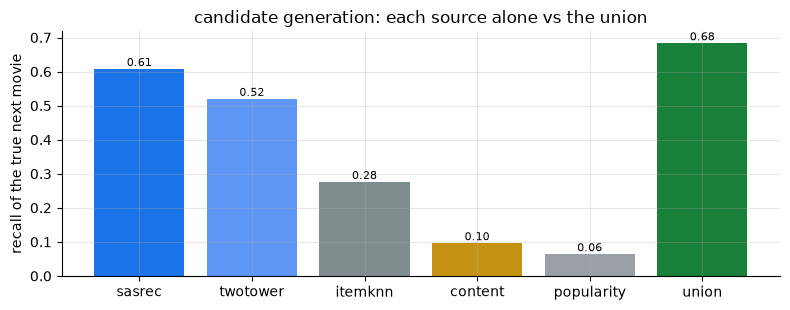

In [10]:
SOURCES = {"sasrec": (sasrec_scores, 100), "twotower": (twotower_scores, 100), "itemknn": (itemknn_scores, 50),
           "content": (content_scorer(E_CONTENT), 50), "popularity": (popularity_scores, 20)}
in_union = np.zeros(len(test), dtype=bool)
recall_by_source = {}
for name, (fn, k) in SOURCES.items():
    hit = RANKS[BEST_CONTENT if name == "content" else name] < k
    recall_by_source[name] = (hit.mean(), hit[IS_COLD].mean()); in_union |= hit
    print(f"{name:12s} top-{k:<3d} recall {hit.mean():.3f} (cold {hit[IS_COLD].mean():.3f})")
print(f"{'union':12s} ~{sum(k for _, k in SOURCES.values())} max  recall {in_union.mean():.3f} (cold {in_union[IS_COLD].mean():.3f})")

fig, ax = plt.subplots(figsize=(8, 3.2))
names = list(recall_by_source) + ["union"]
vals = [recall_by_source[n][0] for n in recall_by_source] + [in_union.mean()]
bars = ax.bar(names, vals, color=[COLORS.get(n, "#188038") for n in names[:-1]] + ["#188038"])
ax.bar_label(bars, fmt="%.2f", fontsize=8); ax.set_ylabel("recall of the true next movie")
ax.set_title("candidate generation: each source alone vs the union"); style(ax)
plt.tight_layout(); plt.show()

**What the numbers say.** SASRec's top 100 already contains the true next movie for 60.8 % of users; the two-tower adds different candidates (52.1 % alone); ItemKNN, content and popularity add a few more. The union of all five reaches **0.684**, 7.6 points more than SASRec alone, and it is the only way new movies enter the candidate set at all (cold recall 0.149, against 0 for SASRec).

The other side of this number is a hard ceiling: for 32 % of users the movie they watched next is not among the ~320 candidates, and no ranker can fix that. When a funnel underperforms, this is the first number to check, because improving retrieval and improving ranking are different projects.

## 6. Ranking: gradient-boosted trees trained to rank

### Learning to rank in brief

A ranker scores each (user, candidate) pair from **features** and sorts. Three ways to train it:

| approach | loss | example |
|---|---|---|
| pointwise | predict each label independently (log-loss on "was this the next movie?") | logistic regression, a binary GBDT |
| pairwise | prefer the positive to each negative: $\log(1 + e^{-(s_+ - s_-)})$ | RankNet |
| listwise | optimise the quality of the whole ordered list | **LambdaMART**, softmax / XE-NDCG |

**LambdaMART** (Burges, 2010) is gradient-boosted trees whose gradients are pairwise RankNet gradients **weighted by how much swapping the two items would change nDCG**, so the trees concentrate on the top of the list. It has been the default industrial ranker for over a decade (search engines, e-commerce, Kaggle recommender competitions) because trees handle heterogeneous features (scores, counts, categories, ratios) without scaling, train in minutes and are easy to inspect. LightGBM implements it as `objective="lambdarank"`.

### Training a ranker without fooling yourself

A first version of this section trained the ranker on the validation event, one positive per user, and it did **not** beat SASRec. Two problems, both well known in practice (and the recipe of RecTools' two-stage models and of the top Kaggle OTTO solutions):

1. **Too few labels.** One positive per user is about 4,000 query groups, and SASRec's own score is already the best feature for exactly this objective, so the trees relearn "sort by SASRec" plus noise. The fix is **more label groups**: fit the retrieval models on each user's history *minus the last R events*, and turn each of those R events into a ranker query (here R = 8, about 48,000 groups), with 50 negatives sampled from the candidates.
2. **Features the first stage cannot see.** If every feature is a retrieval score, the ranker has nothing new to combine. MovieLens has signals SASRec ignores: the **explicit ratings** (how well a movie is liked, not only watched), the user's rating pattern per genre, **demographics**, **co-visitation** with the last 1, 5 and 20 movies, the time since the previous event and what was **trending** in the week before the request.

One more feature brings the LLM in the way the evidence supports (as an extra signal, not a replacement): `llm_keyword_sim`, the similarity between a candidate's LLM keywords and the keywords of the user's recent movies, embedded on their own. An **ablation** (the same ranker trained without that one feature) tells us whether it earns its place.

Everything a feature uses is computed from the data its retrieval models were fit on, so the ranker is trained on the same kind of inputs it gets at serving time and never sees the future. At serving time the candidates and scores come from the models of sections 2 to 4.

In [11]:
import lightgbm as lgb
R_EVENTS, NEG = 8, 50
DEMO = {u: (float(g == "F"), float(a), float(o)) for u, (g, a, o) in ml.demographics.items()}
ITEM_TIMES = [[] for _ in range(N + 1)]
for u in users:
    for t_, i, _ in ml.events[u]: ITEM_TIMES[i].append(t_)
ITEM_TIMES = [np.sort(np.array(x)) for x in ITEM_TIMES]

def base_data(cut):
    """Each user's events except the last `cut`, without cold movies, as (items, ratings, times)."""
    out = []
    for u in users:
        e = [x for x in ml.events[u][:len(ml.events[u]) - cut] if x[1] not in cold]
        out.append(([x[1] for x in e], [x[2] for x in e], [x[0] for x in e]))
    return out

class BaseStats:
    """Popularity, smoothed ratings and co-visitation, computed from one specific slice of the data."""
    def __init__(self, data):
        seqs = [d[0] for d in data]
        self.pop = torch.tensor(np.bincount([i for s in seqs for i in s], minlength=N + 1), dtype=torch.float, device=device)
        rs, rc = np.zeros(N + 1), np.zeros(N + 1)
        for s, r, _ in data: np.add.at(rs, s, r); np.add.at(rc, s, 1)
        self.item_mean = torch.tensor((rs + 3.6 * 10) / (rc + 10), dtype=torch.float, device=device)   # shrunk toward the global mean
        self.user_mean = [float(np.mean(r)) if r else 3.6 for _, r, _ in data]
        C = torch.zeros(N + 1, N + 1, device=device)                     # co-visitation within 5 steps, both directions
        for s in seqs:
            if len(s) < 2: continue
            st = torch.tensor(s, device=device)
            for w in range(1, 6):
                a, b = st[:-w], st[w:]; one = torch.ones_like(a, dtype=torch.float)
                C.index_put_((a, b), one, accumulate=True); C.index_put_((b, a), one, accumulate=True)
        self.covis = torch.log1p(C)

def knn_from(seqs):
    X = torch.zeros(len(seqs), N + 1, device=device)
    for r_, s in enumerate(seqs): X[r_, s] = 1
    Xn = X / (X.norm(dim=0, keepdim=True) + 1e-8); S = Xn.T @ Xn; S.fill_diagonal_(0)
    def score(H):
        out = torch.zeros(len(H), N + 1, device=device)
        for j, h in enumerate(H):
            if h: items, w = recency(h); out[j] = (S[items] * w[:, None]).sum(0)
        return out
    return score

In [12]:
K_CAND = {name: k for name, (_, k) in SOURCES.items()}; SRC = list(K_CAND)
FEATS = ([f"{n}_{x}" for n in SRC for x in ("score", "rank", "gap", "z")] +
         ["sasrec_prob", "log_pop", "is_cold", "year", "genre_affinity", "history_len", "n_sources", "year_gap", "trend_7d", "trend_30d",
          "item_mean_rating", "user_mean_rating", "user_genre_rating", "covis_last1", "covis_last5", "covis_last20", "days_since_prev",
          "gender_f", "age", "occupation", "llm_keyword_sim"])

def build_features(events, sources, st, neg=None, seed=0, B=256):
    """events: (user row, history items, history ratings, history times, target, request time) -> per-query feature matrices."""
    rng = np.random.default_rng(seed); Xs, ys, cands = [], [], []
    for b in range(0, len(events), B):
        chunk = events[b:b + B]; H = [e[1] for e in chunk]
        S = {n: fn(H) for n, fn in sources.items()}
        for n in S:
            S[n][:, 0] = -1e9
            for j, h in enumerate(H):
                if h: S[n][j, torch.tensor(h, device=device)] = -1e9
        Rk = {n: torch.empty_like(s, dtype=torch.long).scatter_(1, s.argsort(1, descending=True), torch.arange(N + 1, device=device).repeat(len(H), 1)) for n, s in S.items()}
        cand = torch.zeros_like(S["sasrec"], dtype=torch.bool)
        for n, k in K_CAND.items(): cand |= Rk[n] < k
        n_src = sum((Rk[n] < k).float() for n, k in K_CAND.items())
        for j, (ur, h, hr, ht, t, tq) in enumerate(chunk):
            c = cand[j].nonzero().squeeze(1)
            if neg is not None:                                          # training query: the positive + sampled negatives
                if not bool((c == t).any()): continue
                negs = c[c != t].cpu().numpy(); negs = rng.choice(negs, size=min(neg, len(negs)), replace=False)
                c = torch.tensor(np.concatenate([[t], negs]), device=device)
            hh = torch.tensor(h[-20:] or [0], device=device); gi = G[c]
            cols = []
            for n in SRC:
                allv = S[n][j][cand[j]]; v = S[n][j, c]
                cols += [v, Rk[n][j, c].float(), v - allv.max(), (v - allv.mean()) / (allv.std() + 1e-6)]
            prob = torch.zeros(N + 1, device=device); prob[cand[j]] = torch.softmax(S["sasrec"][j, cand[j]], 0)
            hr_t = torch.tensor(hr[-50:] or [3.6], device=device, dtype=torch.float); hg = G[torch.tensor(h[-50:] or [0], device=device)]
            g_mean = (hg * hr_t[:, None]).sum(0) / (hg.sum(0) + 1e-6) - st.user_mean[ur]; g_mean[hg.sum(0) == 0] = 0
            ones = torch.ones(len(c), device=device)
            ts_feat = []
            for i in c.tolist():
                ts = ITEM_TIMES[i]; nb_ = np.searchsorted(ts, tq)
                ts_feat.append((0.0, 0.0) if i in cold else (np.log1p(nb_ - np.searchsorted(ts, tq - 7 * 86400)), np.log1p(nb_ - np.searchsorted(ts, tq - 30 * 86400))))
            gender, age, occ = DEMO[users[ur]]
            cols += [prob[c], torch.log1p(st.pop[c]), COLD[c].float(), YR[c], (gi @ G[hh].mean(0)) / (gi.sum(1) + 1e-6), ones * len(h), n_src[j, c],
                     (YR[c] - YR[hh].mean()).abs()]
            tail = [st.item_mean[c], ones * st.user_mean[ur], (gi @ g_mean) / (gi.sum(1) + 1e-6),
                    st.covis[hh[-1:]][:, c].sum(0), st.covis[hh[-5:]][:, c].sum(0), st.covis[hh][:, c].sum(0),
                    ones * ((tq - ht[-1]) / 86400 if ht else -1.0), ones * gender, ones * age, ones * occ,
                    E_KW[c] @ F.normalize(E_KW[hh].mean(0), dim=0)]          # LLM keywords: candidate vs the user's recent movies
            Xs.append(np.column_stack([torch.stack(cols, 1).cpu().numpy(), np.array(ts_feat, dtype=np.float32), torch.stack(tail, 1).cpu().numpy()]))
            ys.append((c.cpu().numpy() == t).astype(int)); cands.append(c.cpu().numpy())
    return Xs, ys, cands

def serving_events(drop):
    out = []
    for ur, u in enumerate(users):
        e = ml.events[u]; p = len(e) - drop; hist = [x for x in e[:p] if x[1] not in cold]
        out.append((ur, [x[1] for x in hist], [x[2] for x in hist], [x[0] for x in hist], e[p][1], e[p][0]))
    return out

In [13]:
# 1) retrieval models fit on older data; the R most recent training events per user become ranker queries
t0 = time.time()
early = base_data(2 + R_EVENTS); st_early = BaseStats(early); early_seqs = [d[0] for d in early]
rank_events = []
for ur, u in enumerate(users):
    e = ml.events[u]
    for p in range(len(e) - 2 - R_EVENTS, len(e) - 2):
        hist = [x for x in e[:p] if x[1] not in cold]
        rank_events.append((ur, [x[1] for x in hist], [x[2] for x in hist], [x[0] for x in hist], e[p][1], e[p][0]))
sasrec_early, _ = train_sasrec(early_seqs, max_steps=max(st_ for st_, _, _ in curve), eval_split=None, log=False)   # same length as the main model
tt_early, _, _ = train_twotower(early_seqs, E_TT)
early_sources = {"sasrec": scorer(sasrec_early), "twotower": tt_early, "itemknn": knn_from(early_seqs),
                 "content": content_scorer(E_CONTENT), "popularity": lambda H: torch.log1p(st_early.pop).repeat(len(H), 1)}
X_tr, y_tr, _ = build_features(rank_events, early_sources, st_early, neg=NEG)
del sasrec_early, tt_early, early_sources; torch.cuda.empty_cache() if device == "cuda" else None
print(f"ranker training data: {len(rank_events):,} events -> {len(X_tr):,} queries with the target among the candidates, "
      f"{sum(len(y) for y in y_tr):,} rows ({time.time() - t0:.0f}s)")

# 2) serving: candidates and features from the models of sections 2-4, for the validation and the test event
st_serve = BaseStats(base_data(2))
serve_sources = {n: fn for n, (fn, _) in SOURCES.items()}
X_va, y_va, c_va = build_features(serving_events(2), serve_sources, st_serve)
X_te, y_te, c_te = build_features(serving_events(1), serve_sources, st_serve)
print(f"validation and test candidates scored ({time.time() - t0:.0f}s)")

ranker training data: 48,320 events -> 35,762 queries with the target among the candidates, 1,823,862 rows (563s)


validation and test candidates scored (672s)


In [14]:
def query_ranks(preds, ys):
    """Rank of the target inside each query's candidate list; 10**6 if retrieval missed it."""
    return np.array([int((p > p[y.argmax()]).sum()) if y.any() else 10 ** 6 for p, y in zip(preds, ys)])

va_keep = [i for i, y in enumerate(y_va) if y.any()]
train_set = lgb.Dataset(np.concatenate(X_tr), np.concatenate(y_tr), group=[len(y) for y in y_tr], feature_name=FEATS,
                        categorical_feature=["occupation"])
valid_set = lgb.Dataset(np.concatenate([X_va[i] for i in va_keep]), np.concatenate([y_va[i] for i in va_keep]),
                        group=[len(y_va[i]) for i in va_keep], reference=train_set)
params = dict(objective="lambdarank", metric="ndcg", eval_at=[10], lambdarank_truncation_level=20, learning_rate=0.05, num_leaves=63,
              min_data_in_leaf=100, feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1, verbose=-1, seed=0)
t0 = time.time()
ranker = lgb.train(params, train_set, num_boost_round=3000, valid_sets=[valid_set], callbacks=[lgb.early_stopping(100, verbose=False)])
print(f"LambdaMART: {ranker.best_iteration} trees in {time.time() - t0:.0f}s")

# the gate: does the ranker beat SASRec's own order on the validation event?
sas_col = FEATS.index("sasrec_score")
nd = lambda r: np.where(r < 10, 1 / np.log2(r + 2), 0.0)
r_va_sas = query_ranks([x[:, sas_col] for x in X_va], y_va)
r_va_rk = query_ranks([ranker.predict(x, num_iteration=ranker.best_iteration) for x in X_va], y_va)
gate = paired_bootstrap_diff(nd(r_va_sas), nd(r_va_rk))
print(f"validation nDCG@10: SASRec {nd(r_va_sas).mean():.4f} | ranker {nd(r_va_rk).mean():.4f} | diff {gate[0]:+.4f} [{gate[1]:+.4f}, {gate[2]:+.4f}]")
USE_RANKER = gate[1] > 0
print("gate:", "PASS, the ranker goes into the system" if USE_RANKER else "FAIL, the system keeps SASRec's order")

# Ablation: does the LLM-keyword feature earn its place? Retrain without it and compare on validation.
keep_cols = [k for k, f in enumerate(FEATS) if f != "llm_keyword_sim"]
abl_train = lgb.Dataset(np.concatenate(X_tr)[:, keep_cols], np.concatenate(y_tr), group=[len(y) for y in y_tr],
                        feature_name=[FEATS[k] for k in keep_cols], categorical_feature=["occupation"])
abl_valid = lgb.Dataset(np.concatenate([X_va[i] for i in va_keep])[:, keep_cols], np.concatenate([y_va[i] for i in va_keep]),
                        group=[len(y_va[i]) for i in va_keep], reference=abl_train)
ranker_no_llm = lgb.train(params, abl_train, num_boost_round=3000, valid_sets=[abl_valid], callbacks=[lgb.early_stopping(100, verbose=False)])
r_va_abl = query_ranks([ranker_no_llm.predict(x[:, keep_cols], num_iteration=ranker_no_llm.best_iteration) for x in X_va], y_va)
d_llm = paired_bootstrap_diff(nd(r_va_abl), nd(r_va_rk))
print(f"validation nDCG@10 with vs without the LLM-keyword feature: {d_llm[0]:+.4f} [{d_llm[1]:+.4f}, {d_llm[2]:+.4f}]")

LambdaMART: 247 trees in 26s


validation nDCG@10: SASRec 0.1797 | ranker 0.1857 | diff +0.0059 [+0.0022, +0.0096]
gate: PASS, the ranker goes into the system


validation nDCG@10 with vs without the LLM-keyword feature: +0.0012 [-0.0012, +0.0035]


sasrec                     hit@10 0.293  ndcg@10 0.172  mrr 0.148  | warm hit@10 0.334 | cold hit@10 0.000
ranker (LambdaMART)        hit@10 0.307  ndcg@10 0.181  mrr 0.156  | warm hit@10 0.349 | cold hit@10 0.009
test hit@10 ranker - SASRec: +0.0137  95% CI [+0.0065, +0.0209]


test ndcg@10 ranker - SASRec: +0.0092  95% CI [+0.0055, +0.0128]
only users whose next movie was retrieved (68%): ndcg@10 diff +0.0135 [+0.0083, +0.0187]


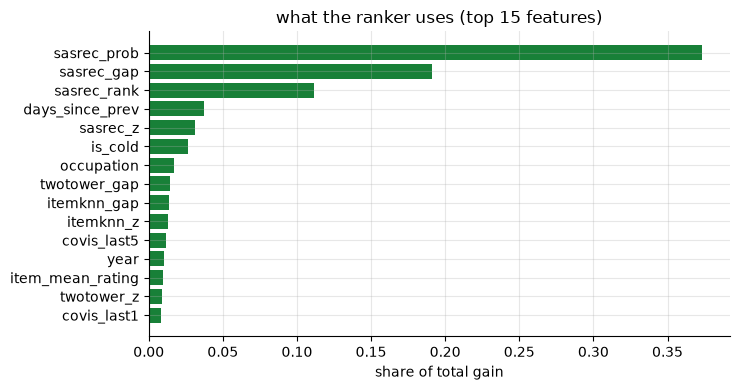

In [15]:
PRED_TE = [ranker.predict(x, num_iteration=ranker.best_iteration) for x in X_te]
RANKS["ranker"] = query_ranks(PRED_TE, y_te)
summary("sasrec", RANKS["sasrec"]); summary("ranker (LambdaMART)", RANKS["ranker"])
for metric, f in (("hit@10", lambda r: (r < 10).astype(float)), ("ndcg@10", nd)):
    d = paired_bootstrap_diff(f(RANKS["sasrec"]), f(RANKS["ranker"]))
    print(f"test {metric} ranker - SASRec: {d[0]:+.4f}  95% CI [{d[1]:+.4f}, {d[2]:+.4f}]")
retrieved = np.array([y.any() for y in y_te])
d = paired_bootstrap_diff(nd(RANKS["sasrec"])[retrieved], nd(RANKS["ranker"])[retrieved])
print(f"only users whose next movie was retrieved ({retrieved.mean():.0%}): ndcg@10 diff {d[0]:+.4f} [{d[1]:+.4f}, {d[2]:+.4f}]")

gain = ranker.feature_importance("gain"); order = np.argsort(-gain)[:15]
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.barh([FEATS[i] for i in order][::-1], (gain[order] / gain.sum())[::-1], color=COLORS["ranker"])
ax.set_xlabel("share of total gain"); ax.set_title("what the ranker uses (top 15 features)"); style(ax)
plt.tight_layout(); plt.show()

**What the numbers say.** The industry recipe works. With 35,762 training queries (1.8 million rows) instead of one positive per user, LambdaMART passes the gate on validation (nDCG@10 +0.0059, 95 % CI [+0.0022, +0.0096]) and holds up on test: **hit@10 0.293 → 0.307 (+1.4 points, CI [+0.7, +2.1]) and nDCG@10 0.172 → 0.181 (+5 % relative)**. Among the 68 % of users whose next movie was retrieved, the gain is larger (+0.0135 nDCG). Gains of a few percent are what second-stage rankers typically add over a strong first stage, and at a platform's scale they are worth a lot.

The feature importance tells the story of how. The SASRec features (its probability, its gap to the user's best candidate, its rank) carry most of the gain: the ranker starts from SASRec's opinion. What it adds comes from signals SASRec cannot see: the time since the user's previous rating, whether a movie is new, the user's occupation, co-visitation with the last five movies, the release year, the average rating. Each one is small; together they move the needle.

The LLM-keyword feature did not earn its place: the ablation gives +0.0012 nDCG on validation with an interval that includes 0 ([-0.0012, +0.0035]), and it is not among the top 15 features. A production team would drop it, since it costs an hour of LLM time per catalog refresh and buys nothing measurable.

## 7. Re-ranking: exploration for new movies, and diversity

### Exploration slots

Nothing collaborative can recommend a movie nobody has watched: SASRec, ItemKNN and the ranker all score cold movies at zero. But a platform that never shows new items never learns about them, which is the **exploration/exploitation** dilemma. Production systems solve it with **bandits** (Spotify's BaRT; Thompson sampling or UCB per slot): give uncertain items some exposure, learn from the response, and shift exposure to what works. The simplest offline-measurable version is a **reserved slot**: keep the top 9 of the ranking and give the 10th position to the best-scoring new movie according to a content-aware score. It costs a little accuracy on the warm items and buys reach for new ones; how much of each is a product decision, and the curve below is what you would bring to that discussion.

validation, cold targets ranked among 370 new movies by twotower    : hit@1 0.051 hit@3 0.102


validation, cold targets ranked among 370 new movies by content+llm : hit@1 0.017 hit@3 0.039


validation, cold targets ranked among 370 new movies by content     : hit@1 0.027 hit@3 0.072


validation, cold targets ranked among 370 new movies by llm keywords: hit@1 0.013 hit@3 0.035
new-movie slot filled by: twotower
ranker + 0 new-movie slot(s) hit@10 0.307  ndcg@10 0.181  mrr 0.156  | warm hit@10 0.349 | cold hit@10 0.009


ranker + 1 new-movie slot(s) hit@10 0.300  ndcg@10 0.179  mrr 0.155  | warm hit@10 0.336 | cold hit@10 0.044


ranker + 2 new-movie slot(s) hit@10 0.290  ndcg@10 0.176  mrr 0.155  | warm hit@10 0.321 | cold hit@10 0.074


ranker + 3 new-movie slot(s) hit@10 0.275  ndcg@10 0.171  mrr 0.154  | warm hit@10 0.300 | cold hit@10 0.094


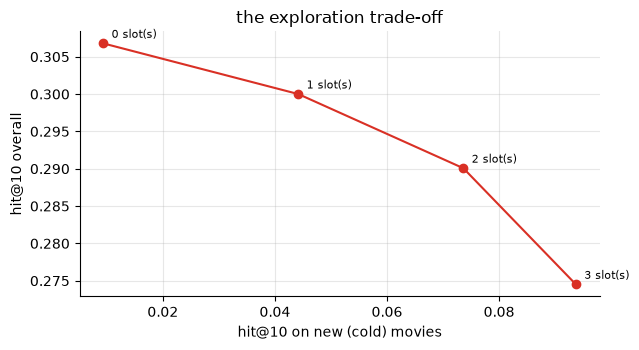

In [16]:
FINAL = "ranker" if USE_RANKER else "sasrec"
final_lists = []
for j, (h, t) in enumerate(test):
    if FINAL == "ranker":
        order = c_te[j][np.argsort(-PRED_TE[j])]
    else:
        order = None
    final_lists.append(order)
if FINAL == "sasrec":
    S_all = torch.cat([sasrec_scores([h for h, _ in test[b:b + 512]]) for b in range(0, len(test), 512)])
    for j, (h, _) in enumerate(test):
        s = S_all[j].clone(); s[0] = -1e9
        if h: s[torch.tensor(h, device=device)] = -1e9
        final_lists[j] = s.topk(300).indices.cpu().numpy()

# Which score should pick the new movie? Both candidates place cold movies without collaborative data; choose on VALIDATION
# (users whose validation target is a cold movie: rank it among the cold movies only).
cold_idx = torch.tensor(sorted(cold), device=device)
def all_scores(fn, split):
    return torch.cat([fn([h for h, _ in split[b:b + 512]]) for b in range(0, len(split), 512)])
va_cold = [j for j, (_, t) in enumerate(valid) if t in cold]
pos = {int(i): k for k, i in enumerate(cold_idx.tolist())}
choice = {}
for name, fn in (("twotower", twotower_scores), ("content+llm", content_scorer(E_LLM)), ("content", content_scorer(E_META)),
                 ("llm keywords", content_scorer(E_KW))):
    S_va = all_scores(fn, [valid[j] for j in va_cold])[:, cold_idx]
    r = np.array([int((S_va[k] > S_va[k, pos[valid[j][1]]]).sum()) for k, j in enumerate(va_cold)])
    choice[name] = (r < 1).mean(); print(f"validation, cold targets ranked among {len(cold)} new movies by {name:12s}: hit@1 {(r < 1).mean():.3f} hit@3 {(r < 3).mean():.3f}")
SLOT_SCORE = max(choice, key=choice.get); print("new-movie slot filled by:", SLOT_SCORE)
SLOT_FN = {"twotower": twotower_scores, "content+llm": content_scorer(E_LLM), "content": content_scorer(E_META),
           "llm keywords": content_scorer(E_KW)}[SLOT_SCORE]
TT_all = all_scores(SLOT_FN, test)
def with_slots(j, slots):
    order = list(final_lists[j])
    if slots == 0: return order
    seen = set(test[j][0]); cs = TT_all[j, cold_idx]; best = cold_idx[cs.argsort(descending=True)].tolist()
    new = [i for i in best if i not in seen][:slots]
    top = [i for i in order if i not in new][:10 - slots] + new
    return top + [i for i in order if i not in set(top)]
def rank_of(lst, t):
    return lst.index(t) if t in lst else 10 ** 6
trade = {}
for slots in range(0, 4):
    r = np.array([rank_of(with_slots(j, slots), t) for j, (_, t) in enumerate(test)])
    trade[slots] = summary(f"{FINAL} + {slots} new-movie slot(s)", r)
    if slots == 1: RANKS["explore"] = r

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot([trade[s]["cold"][0] for s in trade], [trade[s]["all"][0] for s in trade], "o-", color=COLORS["explore"])
for s in trade: ax.annotate(f"{s} slot(s)", (trade[s]["cold"][0], trade[s]["all"][0]), textcoords="offset points", xytext=(6, 4), fontsize=8)
ax.set_xlabel("hit@10 on new (cold) movies"); ax.set_ylabel("hit@10 overall"); ax.set_title("the exploration trade-off"); style(ax)
plt.tight_layout(); plt.show()

**What the numbers say.** On validation, the two-tower model was the best at ranking a new movie among the 370 new ones (hit@1 0.051, against 0.027 for content and 0.013 for the LLM keywords), so it fills the slot. One reserved slot takes cold hit@10 from 0.009 to **0.044** (five times more) at a cost of 0.7 points of overall hit@10 (0.307 → 0.300). Each further slot costs about 1 to 1.5 points overall and buys about 2 to 3 points on new movies. New movies are 12 % of the test events (747 of 6,040), so this is not a corner case.

Where to stop is a product decision, not a modelling one: how much short-term accuracy is it worth to give new releases an audience and to learn what they are worth? A bandit makes that decision adaptively, per item, from the responses it gets; the curve is what you need to set up the discussion.

### Diversity with maximal marginal relevance

A list of ten nearly identical movies is accurate and boring, and it narrows what the user discovers. **MMR** (Carbonell and Goldstein, 1998) builds the list greedily, each time picking the candidate that maximises

$$\lambda \cdot \text{relevance}(i) - (1 - \lambda) \cdot \max_{j \in \text{selected}} \text{sim}(i, j)$$

so a candidate that is very similar to something already chosen is penalised. With $\lambda = 1$ it is the plain ranking; lowering $\lambda$ trades accuracy for **intra-list diversity**. Here similarity is the overlap of the two movies' genre sets (Jaccard), and diversity is one minus the mean pairwise overlap of the ten movies: easy to interpret, and directly what a user notices (ten comedies, or a mix). Relevance is the position in the ranker's list, scaled from 1 to 0. Spotify and Netflix both describe diversity and "calibration" (matching the genre mix of a user's history, Steck, 2018) as explicit objectives of their final layer.

lambda 1.0: hit@10 0.307  ndcg@10 0.181  intra-list diversity 0.659


lambda 0.8: hit@10 0.303  ndcg@10 0.177  intra-list diversity 0.719


lambda 0.6: hit@10 0.288  ndcg@10 0.169  intra-list diversity 0.775


lambda 0.4: hit@10 0.255  ndcg@10 0.156  intra-list diversity 0.820


lambda 0.2: hit@10 0.222  ndcg@10 0.142  intra-list diversity 0.852


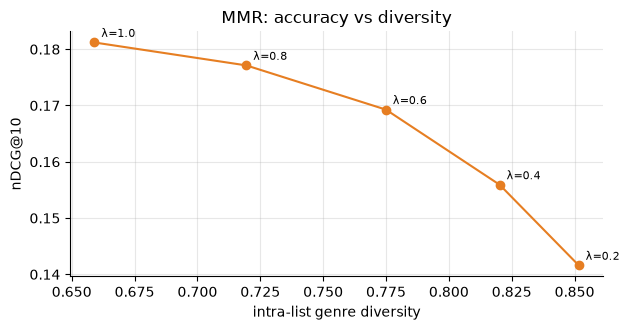

In [17]:
G_NP = G.cpu().numpy()                                                 # many tiny operations: numpy on the CPU is faster here
def genre_sim(items):
    A = G_NP[np.asarray(items)]; inter = A @ A.T; n = A.sum(1)
    return inter / (n[:, None] + n[None, :] - inter + 1e-9)              # Jaccard similarity of the genre sets
def mmr(order, lam, k=10, pool=50):
    cand = np.asarray(order[:pool]); rel = np.linspace(1, 0, len(cand))  # relevance from the position in the ranking
    sim = genre_sim(cand)
    chosen = [0]; best_sim = sim[0].copy()
    while len(chosen) < k:
        score = lam * rel - (1 - lam) * best_sim; score[chosen] = -np.inf
        nxt = int(score.argmax()); chosen.append(nxt); best_sim = np.maximum(best_sim, sim[nxt])
    top = [int(cand[i]) for i in chosen]
    return top + [int(i) for i in order if int(i) not in set(top)]
def diversity(lst):
    S = genre_sim(lst[:10])
    return float(1 - (S.sum() - np.trace(S)) / (10 * 9))                 # 1 - mean pairwise genre overlap
rows_mmr = []
for lam in (1.0, 0.8, 0.6, 0.4, 0.2):
    lists = [mmr(list(final_lists[j]), lam) for j in range(len(test))]
    r = np.array([rank_of(l, t) for l, (_, t) in zip(lists, test)])
    rows_mmr.append((lam, (r < 10).mean(), nd(r).mean(), np.mean([diversity(l) for l in lists])))
    print(f"lambda {lam:.1f}: hit@10 {rows_mmr[-1][1]:.3f}  ndcg@10 {rows_mmr[-1][2]:.3f}  intra-list diversity {rows_mmr[-1][3]:.3f}")
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot([r[3] for r in rows_mmr], [r[2] for r in rows_mmr], "o-", color=COLORS["content+llm"])
for lam, _, n_, d_ in rows_mmr: ax.annotate(f"λ={lam}", (d_, n_), textcoords="offset points", xytext=(5, 4), fontsize=8)
ax.set_xlabel("intra-list genre diversity"); ax.set_ylabel("nDCG@10"); ax.set_title("MMR: accuracy vs diversity"); style(ax)
plt.tight_layout(); plt.show()

**What the numbers say.** The first step is almost free: $\lambda = 0.8$ raises intra-list genre diversity from 0.659 to 0.719 for 0.4 points of hit@10 (0.307 → 0.303). After that the price climbs fast: $\lambda = 0.6$ gives 0.775 for 1.9 points, $\lambda = 0.2$ gives 0.852 for 8.5 points.

Keep in mind what an offline metric can and cannot see. Hit@10 rewards predicting the *one* movie the user watched next, so any change to the list can only look neutral or worse. The benefits of diversity (less fatigue, discovery, users who stay longer) only show in online experiments over weeks. That is why platforms tune this knob with A/B tests rather than with a validation set, and why a cheap first step like $\lambda = 0.8$ is a common default.

## 8. The LLM layer: conversational requests and grounded explanations

Where does a language model add value to a recommender that already has good collaborative models? The evidence (and the previous version of this notebook, where an LLM re-ranker made the list worse) points away from asking a small LLM to *rank* and towards using it for what it is good at: **language**.

1. **Understanding a request.** "A 90s science fiction movie like The Matrix" is easy for an LLM to turn into filters (genre Sci-Fi, years 1990-1999, reference title), and hard for a pure embedding search, which matches words rather than constraints. The LLM produces a structured request (`with_structured_output`, notebook 11); the catalog applies the hard filters; the recommender **personalises inside the filtered set**. This is the pattern behind conversational search at streaming services: the LLM is the front end, the recommender is still the engine.
2. **Explaining.** "Because you watched X and Y" makes recommendations more trusted and easier to act on, and Spotify uses LLM-written explanations at scale. The risk is the LLM inventing reasons or titles. The fix is **grounding**: give it the specific history movies that drove the recommendation and check that the explanation only cites those.

We measure both. For requests: on 20 queries with constraints we can check from the metadata, the share of the top-5 that satisfy them (**constraint satisfaction@5**), against an embedding search over the same item texts. For personalisation: for test users we write a request from the genre and decade of their real next movie, and check whether ranking the filtered set by SASRec finds it more often than ranking by popularity or by similarity to the request.

In [18]:
from typing import Literal, Optional
from pydantic import BaseModel, Field
import difflib
if device == "cuda": torch.cuda.empty_cache()

llm = get_llm()
Genre = Literal[tuple(GEN)]
class MovieRequest(BaseModel):
    """What the user is asking for, as filters a catalog can apply."""
    genres_all: list[Genre] = Field(default_factory=list, description="genres the movie must have, all of them (a 'romantic comedy' needs Romance and Comedy)")
    genres_any: list[Genre] = Field(default_factory=list, description="the movie needs at least one of these genres")
    genres_none: list[Genre] = Field(default_factory=list, description="genres the user explicitly does not want")
    year_min: Optional[int] = Field(None, description="earliest release year, e.g. 1990 for 'the 90s' or 'nothing older than 1990'")
    year_max: Optional[int] = Field(None, description="latest release year, e.g. 1999 for 'the 90s' or 1994 for 'before 1995'")
    reference_titles: list[str] = Field(default_factory=list, description="movies the user names as examples of what they like")
    mood: str = Field("", description="the tone, theme or audience the user describes, in a few words")
structured = llm.with_structured_output(MovieRequest, method="function_calling", include_raw=True)   # most reliable in notebook 11
PARSE = {"ok": 0, "failed": 0}
def parse_request(query):
    """LLM -> MovieRequest. A small model sometimes writes text where a number belongs ('nothing older than 1960');
    with include_raw the error comes back as data instead of an exception, and we fall back to an unfiltered search."""
    out = structured.invoke([("system", SYSTEM), ("user", query)])
    if out["parsed"] is None:
        PARSE["failed"] += 1
        return MovieRequest(mood=query)
    PARSE["ok"] += 1
    return out["parsed"]
SYSTEM = "You turn a movie request into catalog filters. Use only the genres listed in the schema. Leave a field empty when the request does not say it."

def norm_title(t):
    t = re.sub(r"\s*\(\d{4}\)\s*$", "", t); t = re.sub(r"\s*\([^)]*\)\s*$", "", t)
    m = re.match(r"^(.*), (The|A|An)$", t)
    return (f"{m.group(2)} {m.group(1)}" if m else t).lower().strip()
NORM = [""] + [norm_title(t) for t in ml.titles[1:]]
def resolve(title):
    hit = difflib.get_close_matches(title.lower().strip(), NORM[1:], n=1, cutoff=0.8)
    return NORM.index(hit[0]) if hit else None

def filter_mask(req: dict):
    m = torch.ones(N + 1, dtype=torch.bool, device=device); m[0] = False
    for g in req.get("genres_all") or []: m &= G[:, gidx[g]] > 0
    if req.get("genres_any"): m &= G[:, [gidx[g] for g in req["genres_any"]]].sum(1) > 0
    for g in req.get("genres_none") or []: m &= G[:, gidx[g]] == 0
    if req.get("year_min"): m &= YR >= req["year_min"]
    if req.get("year_max"): m &= YR <= req["year_max"]
    return m

popn = torch.log1p(pop) / torch.log1p(pop).max()
def query_vector(text):
    return F.normalize(torch.tensor(emb.embed_query(f"search_query: {text}"), device=device), dim=0)
def recommend(query, k=5, history=None):
    """LLM -> filters; similarity to the referenced movies (or to the request text) + a small popularity prior; SASRec if we know the user."""
    req = parse_request(query)
    mask = filter_mask(req.model_dump())
    refs = [i for i in (resolve(t) for t in req.reference_titles) if i]
    if refs: target = F.normalize(E_LLM[refs].mean(0), dim=0); mask[refs] = False
    else: target = query_vector(req.mood or query)
    if history:
        s = sasrec_scores([history])[0]; mask[torch.tensor(history, device=device)] = False
    else:
        s = E_LLM @ target + 0.1 * popn
    s = s.masked_fill(~mask, -1e9)
    return s.topk(k).indices.tolist(), req
recs, req = recommend("a 90s science fiction movie like The Matrix")
print(req.model_dump(exclude_defaults=True)); print([ml.titles[i] for i in recs])

{'genres_any': ['Sci-Fi'], 'year_max': 1999, 'mood': '90s science fiction like The Matrix'}
['Matrix, The (1999)', 'Total Recall (1990)', 'Thirteenth Floor, The (1999)', 'Fifth Element, The (1997)', 'Terminator 2: Judgment Day (1991)']


In [19]:
EVAL_REQ = json.load(open(os.path.join(ROOT, "data", "recsys", "conversational_eval.json"), encoding="utf-8"))
def satisfies(i, spec, ref):
    gs = set(ml.genres[i]); y = ml.years[i]
    ok = all(g in gs for g in spec.get("genres_all", [])) and (not spec.get("genres_any") or bool(gs & set(spec["genres_any"]))) \
        and not gs & set(spec.get("genres_none", [])) and spec.get("year_min", 0) <= y <= spec.get("year_max", 9999) and i != ref
    if ok and "min_ref_genre_overlap" in spec and ref:
        rg = set(ml.genres[ref]); ok = len(gs & rg) / len(gs | rg) >= spec["min_ref_genre_overlap"]
    return bool(ok)
sat_search, sat_llm = [], []
t0 = time.time()
for spec in EVAL_REQ:
    ref = ml.titles.index(spec["reference"]) if "reference" in spec else None
    s = E_LLM @ query_vector(spec["query"]); s[0] = -1e9
    plain = s.topk(5).indices.tolist()
    recs, req = recommend(spec["query"])
    sat_search.append(np.mean([satisfies(i, spec, ref) for i in plain])); sat_llm.append(np.mean([satisfies(i, spec, ref) for i in recs]))
    print(f"{spec['query'][:44]:44s} search {sat_search[-1]:.1f} | LLM filters {sat_llm[-1]:.1f} | {ml.titles[recs[0]][:34]}")
for name, v in (("embedding search", sat_search), ("LLM -> filters", sat_llm)):
    m_, lo, hi = bootstrap_ci(v); print(f"constraint satisfaction@5, {name:16s}: {m_:.2f}  [{lo:.2f}, {hi:.2f}]")
print(f"({time.time() - t0:.0f}s)")

a 90s science fiction movie like The Matrix  search 0.8 | LLM filters 0.8 | Matrix, The (1999)


an animated movie for kids made before 1995  search 0.0 | LLM filters 0.4 | Ghost in the Shell (Kokaku kidotai


a romantic comedy from the 80s               search 0.4 | LLM filters 0.8 | She's Gotta Have It (1986)


a classic film noir                          search 1.0 | LLM filters 1.0 | Sunset Blvd. (a.k.a. Sunset Boulev


a western from the 60s or 70s                search 1.0 | LLM filters 1.0 | For a Few Dollars More (1965)


a scary horror film from the 1970s           search 1.0 | LLM filters 1.0 | Halloween (1978)


... (10 outputs left out)

a sci-fi horror film like Alien              search 0.6 | LLM filters 0.8 | Aliens (1986)


a thriller from 1998 or later                search 0.6 | LLM filters 1.0 | Eye of the Beholder (1999)


a comedy from the 70s that is not a romance  search 0.2 | LLM filters 0.8 | Jerk, The (1979)


a Disney-style animated musical              search 0.8 | LLM filters 1.0 | Lion King, The (1994)
constraint satisfaction@5, embedding search: 0.60  [0.46, 0.74]
constraint satisfaction@5, LLM -> filters  : 0.87  [0.80, 0.93]
(12s)


In [20]:
# Personalisation inside the request: a request written from each user's real next movie (its genre and decade)
rng = random.Random(0)
sample = rng.sample([j for j, (_, t) in enumerate(test) if t not in cold], 200)
hits = {"popularity": [], "similarity to the request": [], "SASRec (personalised)": []}
t0 = time.time()
for j in sample:
    h, t = test[j]; decade = int(ml.years[t]) // 10 * 10
    query = f"I'm in the mood for a {ml.genres[t][0].lower()} movie from the {decade}s"
    req = parse_request(query).model_dump()
    mask = filter_mask(req); mask[torch.tensor(h, device=device)] = False
    for name, s in (("popularity", popn), ("similarity to the request", E_LLM @ query_vector(req.get("mood") or query) + 0.1 * popn),
                    ("SASRec (personalised)", sasrec_scores([h])[0])):
        hits[name].append(float(t in s.masked_fill(~mask, -1e9).topk(10).indices.tolist()))
for name, v in hits.items():
    m_, lo, hi = bootstrap_ci(v); print(f"hit@10 inside the filtered set, {name:26s}: {m_:.3f}  [{lo:.3f}, {hi:.3f}]")
print(f"({time.time() - t0:.0f}s for {len(sample)} requests; structured-output failures so far: {PARSE['failed']} of {PARSE['ok'] + PARSE['failed']})")

hit@10 inside the filtered set, popularity                : 0.285  [0.220, 0.350]
hit@10 inside the filtered set, similarity to the request : 0.325  [0.260, 0.390]
hit@10 inside the filtered set, SASRec (personalised)     : 0.555  [0.485, 0.620]
(127s for 200 requests; structured-output failures so far: 1 of 221)


**What the numbers say.** The LLM front end satisfies the request's constraints in **87 %** of the top-5 results (95 % CI [0.80, 0.93]) against **60 %** for embedding search over the same texts ([0.46, 0.74]). The gap is exactly where embeddings are weak: date ranges and negations. "A 90s crime movie like Pulp Fiction" goes from 0.0 to 0.8, "a war drama made in the 1990s" from 0.2 to 1.0, "a comedy from the 70s that is not a romance" from 0.2 to 0.8. An embedding knows that two texts are about similar things; it cannot enforce "1990 ≤ year ≤ 1999" or "not Romance". The structured output failed on 1 of 221 requests; the fallback (an unfiltered search) kept the system running.

The misses are instructive too. For "an animated movie for kids made before 1995" the LLM asked for Animation but not Children's, and *Ghost in the Shell* is animated and definitely not for kids. For "like The Matrix" it put the title in `mood` instead of `reference_titles`, so the reference itself was recommended. Both are fixable with better field descriptions or examples, which is how you iterate on a schema.

Personalisation inside the request is where the recommender earns its keep. Among the movies that satisfy a request built from the user's real next movie, ranking by SASRec finds that movie in the top 10 for **55.5 %** of users, against 28.5 % for popularity and 32.5 % for similarity to the request. (The request always contains the target's genre and decade, which makes the setup optimistic in absolute terms; the comparison between the three rankings is what matters.) The division of labour is clear: the LLM understands *what* is asked, the user's history decides *which* of the matching movies.

### Grounded explanations

For a recommended movie we find the three movies in the user's history that are closest to it in SASRec's own item-embedding space (the "because you watched" anchors) and ask the LLM for one sentence that cites them. As a contrast, an *ungrounded* prompt only gets the user's favourite genres. We then scan both explanations for catalog titles (case-sensitive full titles of six or more characters, so that ordinary words such as "romance" do not count as the 1999 film *Romance*, and a title inside a longer one, *Toy Story* in *Toy Story 2*, counts once): citing an anchor is grounded; citing a movie that is **not** in the user's history (presenting it as something they watched or liked) is a fabrication. A scan like this can still miss titles written differently, so treat the rates as estimates and read the examples.

In [21]:
ITEM_EMB = F.normalize(sasrec.tok_emb.weight.detach().float(), dim=1)     # SASRec's input embeddings double as item vectors
def display_title(t):
    t = re.sub(r"\s*\(\d{4}\)\s*$", "", t); t = re.sub(r"\s*\([^)]*\)\s*$", "", t)
    m = re.match(r"^(.*), (The|A|An)$", t)
    return f"{m.group(2)} {m.group(1)}" if m else t
# Case-sensitive full titles of 6+ characters: "a romance" must not count as the 1999 film "Romance",
# and "Toy Story" inside "Toy Story 2" is one citation, not two.
TITLE_PATTERNS = [(i, re.compile(r"(?<!\w)" + re.escape(display_title(ml.titles[i])) + r"(?!\w)"))
                  for i in range(1, N + 1) if len(display_title(ml.titles[i])) >= 6]
def titles_in(text):
    spans = [(m.start(), m.end(), i) for i, pat in TITLE_PATTERNS for m in pat.finditer(text)]
    return {i for s_, e_, i in spans
            if not any(s2 <= s_ and e_ <= e2 and (e2 - s2) > (e_ - s_) for s2, e2, _ in spans)}

grounded_ok, grounded_fab, plain_fab, examples = [], [], [], []
t0 = time.time()
for j in sample[:30]:
    h, _ = test[j]
    rec = int(sasrec_scores([h])[0].masked_fill(torch.isin(torch.arange(N + 1, device=device), torch.tensor(h + [0], device=device)), -1e9).argmax())
    anchors = [h[k] for k in (ITEM_EMB[torch.tensor(h, device=device)] @ ITEM_EMB[rec]).topk(min(3, len(h))).indices.tolist()]
    fav = [g for g, _ in sorted(((g, -int(G[torch.tensor(h, device=device), gidx[g]].sum())) for g in GEN), key=lambda x: x[1])[:3]]
    g_prompt = (f"We recommend the movie {ml.titles[rec]} to a user. The movies in their history that are most similar to it are: "
                f"{'; '.join(ml.titles[a] for a in anchors)}. Write one sentence for the user explaining the recommendation, citing one or two "
                f"of those movies by title. Mention no other movies.")
    p_prompt = (f"We recommend the movie {ml.titles[rec]} to a user whose favourite genres are {', '.join(fav)}. "
                f"Write one sentence for the user explaining the recommendation, mentioning movies they have probably enjoyed.")
    g_text, p_text = (m.content for m in llm.batch([g_prompt, p_prompt]))
    allowed = set(h) | {rec}
    found_g, found_p = titles_in(g_text) - {rec}, titles_in(p_text) - {rec}
    grounded_ok.append(float(bool(found_g & set(anchors)))); grounded_fab.append(float(bool(found_g - allowed))); plain_fab.append(float(bool(found_p - allowed)))
    if len(examples) < 2: examples.append((ml.titles[rec], g_text, p_text))
print(f"grounded prompt  : cites an anchor {np.mean(grounded_ok):.0%} | cites a movie not in the history {np.mean(grounded_fab):.0%}")
print(f"ungrounded prompt: cites a movie not in the history {np.mean(plain_fab):.0%}   ({time.time() - t0:.0f}s, 30 users)")
for rec_t, g_text, p_text in examples:
    print(f"\n{rec_t}\n  grounded  : {g_text}\n  ungrounded: {p_text}")

grounded prompt  : cites an anchor 97% | cites a movie not in the history 7%
ungrounded prompt: cites a movie not in the history 13%   (54s, 30 users)

Erin Brockovich (2000)
  grounded  : We recommend Erin Brockovich (2000) based on your viewing history, as it shares similarities with movies like The Shawshank Redemption (1994) and Galaxy Quest (1999).
  ungrounded: While you typically enjoy genres like Comedy, Drama, and Sci-Fi, you might also enjoy "Erin Brockovich," a powerful and engaging drama that, though not in your usual genre range, offers a compelling story that could resonate with your taste in dramatic narratives.

Usual Suspects, The (1995)
  grounded  : We recommend the movie Usual Suspects, The (1995) to you, as it shares similarities with L.A. Confidential (1997) and Schindler's List (1993), both of which are critically acclaimed films that explore complex narratives and intricate characters, much like Usual Suspects.
  ungrounded: You'd enjoy "Usual Suspects" (1995), 

**What the numbers say.** With anchors, 97 % of the explanations cite one of them, and 7 % (2 of 30) mention a movie that is not in the user's history; without anchors, 13 % (4 of 30) do. With 30 users that difference is suggestive, not conclusive. The examples say more than the rates.

- The **ungrounded** explanations make up *attributes* even when they cite no titles: *The Usual Suspects* is described as delving into "War and Thriller" because the user likes those genres, and it is not a war film. Fluent, plausible and false, which is the dangerous kind of error.
- The **grounded** explanations are true but not always convincing: *Erin Brockovich* "shares similarities with *The Shawshank Redemption* and *Galaxy Quest*". SASRec's item embeddings encode *co-watching*, not content, so the anchors explain faithfully why the model chose the movie, but they do not read like reasons a person would give. Production systems usually pick anchors that are both: close in the model's space and similar in content.

The lesson is the same as for RAG in notebook 10: give the model the evidence, ask it to use only that evidence, and check the output automatically.

## 9. The whole funnel in one table

system                              hit@10  ndcg@10  warm hit@10  cold hit@10
popularity                           0.036    0.018        0.041        0.000
itemknn                              0.125    0.067        0.143        0.000
content                              0.033    0.017        0.031        0.047
content+llm                          0.023    0.012        0.023        0.020
twotower                             0.194    0.109        0.221        0.001
sasrec                               0.293    0.172        0.334        0.000
LambdaMART ranker                    0.307    0.181        0.349        0.009
ranker + 1 new-movie slot            0.300    0.179        0.336        0.044


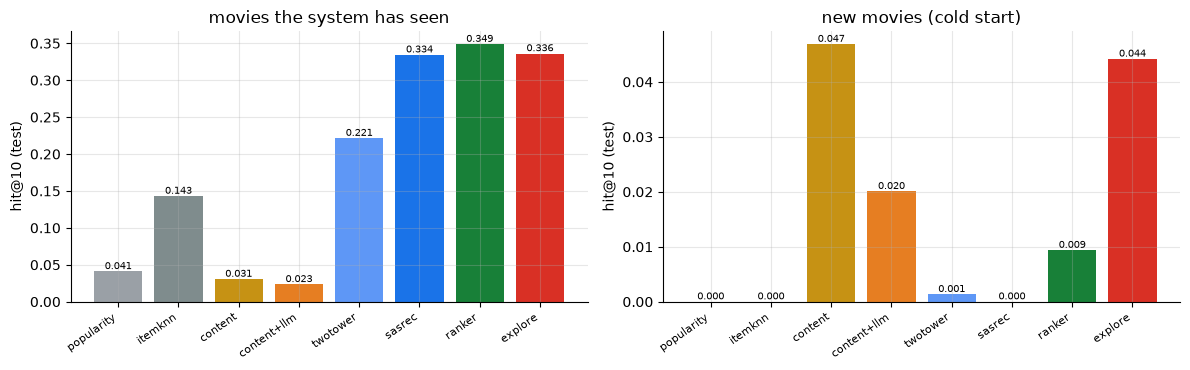

In [22]:
order = ["popularity", "itemknn", "content", "content+llm", "twotower", "sasrec", "ranker", "explore"]
labels = {"explore": f"{FINAL} + 1 new-movie slot", "ranker": "LambdaMART ranker" + ("" if USE_RANKER else " (failed the gate)")}
rows = {n: summary(n, RANKS[n], quiet=True) for n in order}
print(f"{'system':34s} {'hit@10':>7s} {'ndcg@10':>8s} {'warm hit@10':>12s} {'cold hit@10':>12s}")
for n in order:
    r = rows[n]; print(f"{labels.get(n, n):34s} {r['all'][0]:7.3f} {r['all'][1]:8.3f} {r['warm'][0]:12.3f} {r['cold'][0]:12.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a, seg, title in ((ax[0], "warm", "movies the system has seen"), (ax[1], "cold", "new movies (cold start)")):
    vals = [rows[n][seg][0] for n in order]
    bars = a.bar(range(len(order)), vals, color=[COLORS.get(n, "#188038") for n in order])
    a.bar_label(bars, fmt="%.3f", fontsize=7); a.set_xticks(range(len(order))); a.set_xticklabels([n for n in order], rotation=35, ha="right", fontsize=8)
    a.set_ylabel("hit@10 (test)"); a.set_title(title); style(a)
plt.tight_layout(); plt.show()

**Reading the table.** The best system is the full funnel: candidates from five sources and a LambdaMART ranker on top, with **hit@10 0.307 and nDCG@10 0.181**, ahead of the best single model (SASRec, 0.293 / 0.172) with an interval that excludes zero. Adding one slot for new movies trades 0.7 points of overall hit@10 for five times more hits on new releases (0.009 → 0.044). Diversity can be raised almost for free with a light MMR.

Where the LLM helped and where it did not, measured rather than assumed:

| use of the LLM | result |
|---|---|
| keywords mixed into the item text | **worse** (content hit@10 0.033 → 0.023), rejected on validation |
| keywords as a ranker feature | no measurable gain (+0.0012, interval includes 0), not worth its cost |
| understanding requests (structured filters) | **clearly better** (constraint satisfaction 0.60 → 0.87) |
| explanations with anchors from the history | grounded and checkable; fewer invented movies than without anchors |

This matches what the field has found: small LLMs do not beat collaborative models at ranking, but they are excellent at the language around the recommender.

## Takeaways

- **Recommendation is a funnel, and each stage has its own metric.** Retrieval is judged by recall of the candidate set, ranking by nDCG of the final list, the final layer by what it trades (accuracy against exploration and diversity). Measure them separately or you cannot tell where a system fails.
- **The sequence is the strongest signal.** A small decoder-only transformer over movie ids, trained like a language model with full cross-entropy, is the best single model here, which is why the industry is converging on "foundation models" over interaction sequences (Netflix, Meta's HSTU).
- **A second-stage ranker only helps if it has something new to learn from**: many label groups from a later period than the retrieval models, and features the first stage cannot see. Gate it against the first stage on held-out data; a ranker that only relearns the retrieval score is overhead.
- **Cold start is solved by content and exploration, not by collaborative models.** Text and metadata place a new item; a reserved slot gives it exposure; the cost on warm items is explicit.
- **Use LLMs for language.** Offline item enrichment, turning requests into filters and grounded explanations are cheap and measurable. Asking a small LLM to re-rank a strong recommender is the expensive way to make it worse.
- **Report uncertainty.** With a few thousand users a difference of one or two points of hit@10 can be noise; the paired bootstrap tells you which differences to believe.

**What production adds.** Online A/B tests (offline metrics only predict them imperfectly), real bandits instead of a fixed slot, feature stores and streaming updates, sampled-softmax training with $\log Q$ correction at catalog scale, multi-objective ranking (watch time, satisfaction, diversity), and frameworks built for it: TorchRec and FBGEMM (Meta), NVIDIA Merlin, RecTools and RePlay for two-stage pipelines.